# WP0.8 — do learned profiles match Braun Suppl. Cor. 3.2 and §5? (new analysis)

For each condition: learned eigenvalues λ̃_k = DFT of the **mean** connectivity profile, |k| ≤ 10, against
* Cor. 3.2, `supplement` convention: λ_k = (1 + ikωτ) x̂_k / f̂_k (support of y* = x* + τẋ*),
* `methods` convention: training drives the input toward x* (Methods eq. 7); with leaky activation the realised rates
  are F′ = φ(x* filtered by 1/(1 + ikωτ)) and λ_k = x̂_k / F̂′_k,
* the §5 ridge-shrunk versions λ_k |f̂_k|² / (|f̂_k|² + α).

**Effective α (A12, derived here):** RLS from J0 with P(0) = pI minimises Σ_s ‖W r_s − x_s‖² + (1/p)‖W − J0‖² over
the n_s = (#updates per iteration) × (#training iterations) samples. Dividing by n_s N and using Parseval
((1/NT)∫‖Wf − y‖² dt = Σ_k |λ_k f̂_k − ŷ_k|², ‖W_cp‖²_F = Σ_k |λ_k|²) gives α_eff = 1/(p n_s N). This ignores the
noise in the realised rates, which adds its own (much larger) ridge term; the batch-ridge panel separates the two.

**Acceptance (spec WP0.8):** for modes with |f̂_k|² well above the shrinkage scale, the better convention has relative
error < 10%; otherwise the discrepancy is reported as a finding (no parameter tuning).

**Panels:** A eigenvalues for the Fig. 1 condition · B per-mode errors across the WP0.2 sweeps · C batch ridge on
recorded rates (realisation 1, test iteration) · D convention comparison summary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.targets import SequenceSpec
from seqnet.spectral import braun_map as bm

style()
fig = Figure("wp0", "wp0_8_supplement_check")
K = 10; tau = 0.3224; ks = np.arange(1, K + 1)

def compare(amp, width, offset, settings):
    run = wp0.get(amp, width, offset, settings)
    spec = SequenceSpec(amp=amp, width=width, offset=offset)
    cp = cv.profile_from_matrix(run.summary["mean_W"])
    lam = cv.eigs_from_profile(cp)
    cp_nd = cp.copy(); cp_nd[0] = 0.5 * (cp[1] + cp[-1])  # self-weight replaced by its neighbours (Braun line 992)
    lam_nd = cv.eigs_from_profile(cp_nd)
    sp = bm.bump_spectra(spec, tau)
    out = {"learned": np.array([lam[k] for k in ks]), "learned_nodiag": np.array([lam_nd[k] for k in ks]),
           "self_weight": cp[0], "f2": np.abs(sp["f_hat"][ks]) ** 2}
    for conv in ("supplement", "methods"):
        e = bm.required_eigs(spec, tau, K, conv)
        out[conv] = np.array([e[k] for k in ks])
    c = run.meta["config"]
    n_s = ((c["steps_per_iter"] - 1) // c["m"] + 1) * c["n_train"]
    out["alpha"] = 1.0 / (c["p0"] * n_s * c["N"])
    for conv in ("supplement", "methods"):
        out[conv + "_shrunk"] = out[conv] * out["f2"] / (out["f2"] + out["alpha"])
    return out, run

## Panel A — Fig. 1 condition (a = 0.5, σ = 1.7 s, b = 0, final settings)

In [2]:
c1 = Figure("wp0", "braun_fig1").config()["target"]
A, runA = compare(c1["amp"], c1["width"], c1["offset"], "final")
fig.save("A_fig1", k=ks, **{k: v for k, v in A.items()})

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/wp0_8_supplement_check/A_fig1.npz')

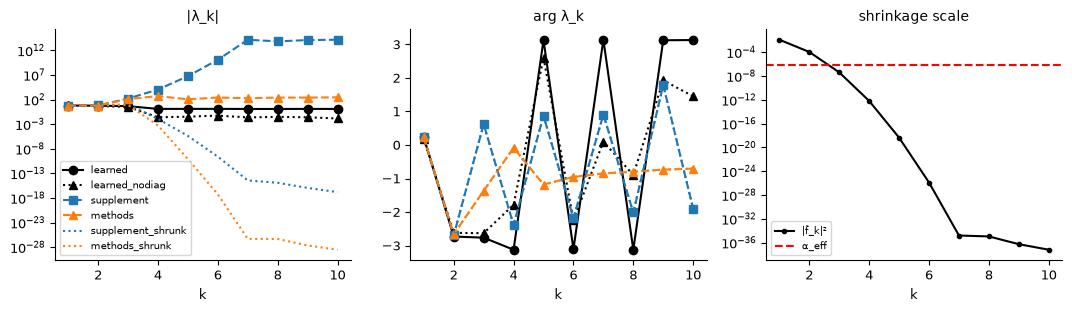

learned    [ 6.171+1.415j -5.417-2.369j -4.421-1.758j -1.305-0.025j -1.329+0.018j]
supplement [      6.067      +1.446j      -6.035      -2.877j
     135.69      +97.012j   -8300.055   -7912.194j
 3844636.141+4581220.767j]
methods    [  6.164  +1.474j  -5.557  -2.892j  26.265-127.399j 529.12  -44.255j
  44.14 -106.662j]


In [3]:
d = fig.load("A_fig1")
F, axs = plt.subplots(1, 3, figsize=(13, 3))
for key, st in [("learned", "ko-"), ("learned_nodiag", "k^:"), ("supplement", "C0s--"), ("methods", "C1^--"), ("supplement_shrunk", "C0:"), ("methods_shrunk", "C1:")]:
    axs[0].semilogy(d["k"], np.abs(d[key]), st, label=key); axs[1].plot(d["k"], np.angle(d[key]), st, label=key)
axs[2].semilogy(d["k"], d["f2"], "k.-", label="|f̂_k|²"); axs[2].axhline(float(d["alpha"]), color="r", ls="--", label="α_eff")
axs[0].set_title("|λ_k|"); axs[1].set_title("arg λ_k"); axs[2].set_title("shrinkage scale"); [a.set_xlabel("k") for a in axs]
axs[0].legend(fontsize=7); axs[2].legend(fontsize=7)
fig.savefig("A_fig1", F); plt.show()
with np.printoptions(precision=3, suppress=True):
    print("learned   ", d["learned"][:5]); print("supplement", d["supplement"][:5]); print("methods   ", d["methods"][:5])

## Panel B — relative error per mode across the WP0.2 sweeps (dev settings), both conventions

In [4]:
cfg2 = Figure("wp0", "braun_fig2").config()
rows = []
for name, key in (("offset_sweep", "offset"), ("width_sweep", "width"), ("amp_sweep", "amp")):
    sw = cfg2[name]
    for v in sw["values"]:
        p = {k: sw[k] for k in ("amp", "width", "offset") if k in sw}; p[key] = v
        o, _ = compare(p["amp"], p["width"], p["offset"], cfg2["settings"])
        rows.append((name, v, o))
E = {conv: np.stack([np.abs(o["learned"] - o[conv]) / np.abs(o[conv]) for _, _, o in rows]) for conv in ("supplement", "methods", "supplement_shrunk", "methods_shrunk")}
E.update({conv + "_nodiag": np.stack([np.abs(o["learned_nodiag"] - o[conv]) / np.abs(o[conv]) for _, _, o in rows]) for conv in ("supplement", "methods")})
fig.save("B_sweeps", labels=np.array([f"{n.split('_')[0]}={v:g}" for n, v, _ in rows]), f2=np.stack([o["f2"] for _, _, o in rows]),
         alpha=np.array([o["alpha"] for _, _, o in rows]), **{f"err_{k}": v for k, v in E.items()})

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/wp0_8_supplement_check/B_sweeps.npz')

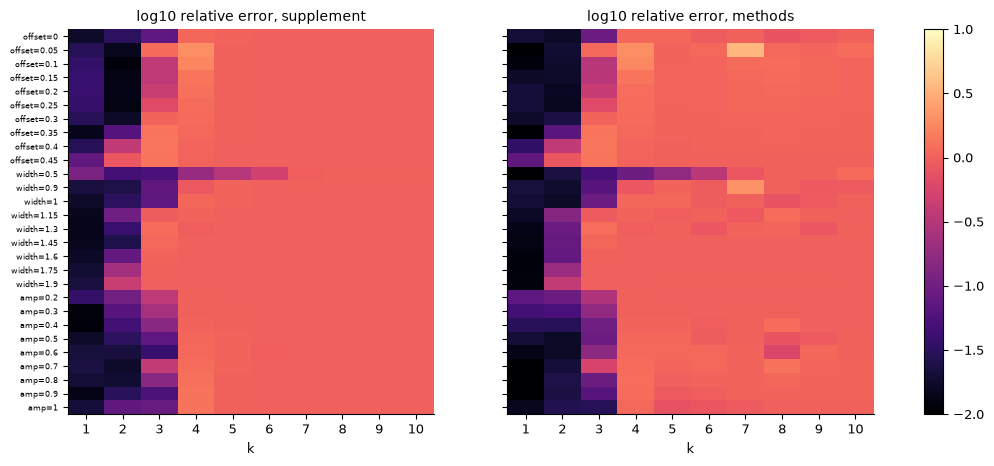

In [5]:
d = fig.load("B_sweeps")
F, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, conv in zip(axs, ["supplement", "methods"]):
    im = ax.imshow(np.log10(d[f"err_{conv}"]), aspect="auto", cmap="magma", vmin=-2, vmax=1)
    ax.set_xticks(range(K), ks); ax.set_xlabel("k"); ax.set_title(f"log10 relative error, {conv}")
axs[0].set_yticks(range(len(d["labels"])), d["labels"], fontsize=6); F.colorbar(im, ax=axs)
fig.savefig("B_sweeps", F); plt.show()

## Panel C — batch ridge on recorded rates

`batch_ridge_W` (spec Section 3.4 fact 4) on realisation 1's recorded test-iteration rates F (N × 131) with targets
x* at the same times, centred on J0 with β = 1/p. This tests the RLS-ridge idealisation on the rates the network
actually produced, including their noise, but with one iteration's samples only.

In [6]:
S = runA.summary; c = runA.meta["config"]
spec = SequenceSpec(amp=c1["amp"], width=c1["width"], offset=c1["offset"])
F_rates = S["R_test0"]; m = c["m"]; n_up = F_rates.shape[1]
tz = runA.summary["t0"][0] + np.arange(n_up) * m * c["dt"]
Y = spec.h_target(tz)
J0 = runA.W0(0)
lam_learn = cv.eigs_from_profile(cv.profile_from_matrix(runA.W(0)))
out = {}
for beta in (1 / c["p0"], 1 / c["p0"] / 10, 1 / c["p0"] * 10):
    Wb = bm.batch_ridge_W(F_rates, Y, J0, beta)
    out[f"beta_{beta:g}"] = np.array([cv.eigs_from_profile(cv.profile_from_matrix(Wb))[k] for k in ks])
fig.save("C_batch", k=ks, learned_r1=np.array([lam_learn[k] for k in ks]), **out)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/wp0_8_supplement_check/C_batch.npz')

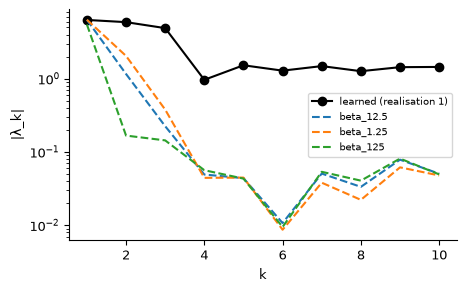

In [7]:
d = fig.load("C_batch")
F, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(d["k"], np.abs(d["learned_r1"]), "ko-", label="learned (realisation 1)")
for k_ in [k for k in d if k.startswith("beta_")]: ax.semilogy(d["k"], np.abs(d[k_]), "--", label=k_)
ax.set_xlabel("k"); ax.set_ylabel("|λ_k|"); ax.legend(fontsize=7)
fig.savefig("C_batch", F); plt.show()

## Panel D — the self-connection shifts every eigenvalue

A diagonal of value s adds s to every λ_k. The learned high-k eigenvalues sit on a floor at the self-weight (phase ±π),
so above the strongly represented modes the learned spectrum is dominated by the diagonal rather than by the sequence.
Errors recomputed with the self-weight replaced by its neighbours (as in Braun's feature pipeline, line 992).

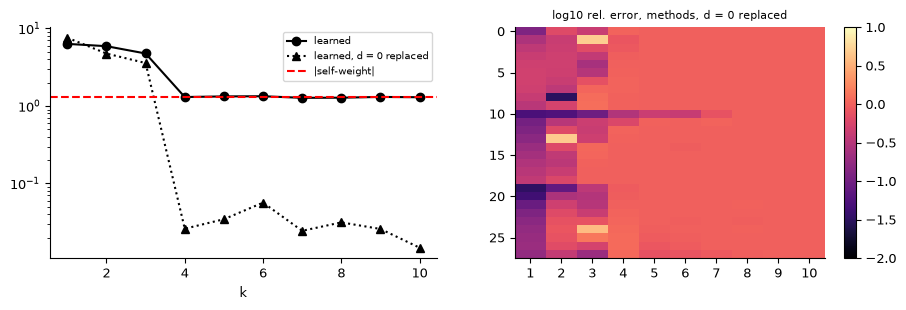

In [8]:
d = fig.load("A_fig1"); b = fig.load("B_sweeps")
F, axs = plt.subplots(1, 2, figsize=(11, 3))
axs[0].semilogy(d["k"], np.abs(d["learned"]), "ko-", label="learned"); axs[0].semilogy(d["k"], np.abs(d["learned_nodiag"]), "k^:", label="learned, d = 0 replaced")
axs[0].axhline(abs(float(d["self_weight"])), color="r", ls="--", label="|self-weight|"); axs[0].legend(fontsize=7); axs[0].set_xlabel("k")
im = axs[1].imshow(np.log10(b["err_methods_nodiag"]), aspect="auto", cmap="magma", vmin=-2, vmax=1); axs[1].set_title("log10 rel. error, methods, d = 0 replaced", fontsize=8)
axs[1].set_xticks(range(K), ks); F.colorbar(im, ax=axs[1])
fig.savefig("D_self_weight", F); plt.show()

## Acceptance

In [9]:
a = fig.load("A_fig1"); b = fig.load("B_sweeps")
strong = a["f2"] > 1e3 * a["alpha"]
errA = {conv: (np.abs(a["learned"] - a[conv]) / np.abs(a[conv]))[strong] for conv in ("supplement", "methods")}
best = min(errA, key=lambda k: np.max(errA[k]))
strong_b = b["f2"] > 1e3 * b["alpha"][:, None]
mx = {conv: float(np.max(b[f"err_{conv}"][strong_b])) for conv in ("supplement", "methods", "supplement_nodiag", "methods_nodiag")}
k12 = {conv: float(np.max(b[f"err_{conv}"][:, :2])) for conv in ("supplement", "methods", "supplement_nodiag", "methods_nodiag")}
fig.checks([
    {"item": "Fig. 1 condition: better convention within 10% on strong modes", "criterion": "max relative error < 0.1 on modes with |f_k|^2 > 1e3 alpha_eff",
     "value": {"best": best, "max_err": {k: float(np.max(v)) for k, v in errA.items()}, "modes": a["k"][strong]}, "passed": bool(np.max(errA[best]) < 0.1)},
    {"item": "WP0.2 sweeps: max relative error on strong modes", "criterion": "reported per convention", "value": mx, "passed": None},
    {"item": "WP0.2 sweeps: max relative error at k = 1, 2", "criterion": "reported per convention (with and without the self-weight)", "value": k12, "passed": None},
])

[PASS] Fig. 1 condition: better convention within 10% on strong modes: {'best': 'methods', 'max_err': {'supplement': 0.017296673088966322, 'methods': 0.009379951351745814}, 'modes': array([1])}
[info] WP0.2 sweeps: max relative error on strong modes: {'supplement': 0.8554996625275461, 'methods': 0.8534489035892029, 'supplement_nodiag': 0.7561293609760533, 'methods_nodiag': 0.8179143797540934}
[info] WP0.2 sweeps: max relative error at k = 1, 2: {'supplement': 0.8554996625275461, 'methods': 0.8534489035892029, 'supplement_nodiag': 4.639239775339993, 'methods_nodiag': 4.759727296054881}


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/wp0_8_supplement_check/acceptance.json')